# TiNA Predictive Maintenance Capstone

**Week 3 goal:** verify the source schema, time coverage, missingness, and maintenance/alarm episodes before preprocessing. This is the project's single TiNA notebook; later weeks can add clearly labeled sections below.

The official source is [ari-dasci/OD-TINA](https://github.com/ari-dasci/OD-TINA). The full dataset is too large for routine laptop analysis, so this notebook uses the documented three-day Week 2 pilot. Do not commit source data or oversized notebook outputs.

## Reproducibility record

Verified Week 2 pilot record:

- Source: `ari-dasci/OD-TINA` commit `927b1584ea4aeac2ac7daa084a82f899b114419b`; downloaded 2026-09-21.
- Local file: `data/raw/tina_sample_2017-09-08_to_10.parquet`. The build script verifies pinned source-partition hashes; the original combined-file SHA-256 is only a writer-dependent reference in the Week 2 record.
- Selected period: 2017-09-08 00:00:00 through 2017-09-10 23:59:59 UTC. This contiguous three-day window fits in laptop memory and contains maintenance and alarm activity.
- Analyst: PROJ 613 project team (Ganesh Mishra, Lakshya Sharma, and Sagar Patel).

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import polars as pl

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.build_week2_subset import (
    OUTPUT_PATH as DATA_PATH,
    UPSTREAM_COMMIT,
    main as build_week2_subset,
)
from src.data_utils import scan_tina, validate_event_columns

build_week2_subset()  # Verifies the pinned source partitions and rebuilds the local pilot.

EXPECTED_PILOT_ROWS = 259_200
print(f'Official TiNA source commit: {UPSTREAM_COMMIT}')
print(f'Verified local subset: {DATA_PATH.relative_to(PROJECT_ROOT)}')
print(f'Expected pilot rows: {EXPECTED_PILOT_ROWS:,}')

Created: data/raw/tina_sample_2017-09-08_to_10.parquet
Rows: 259,200
Maintenance rows: 4,994
Alarm rows: 26,719
Local output SHA-256 (informational): 19365a40e99083c37c9909f25b281caad6e47430c52b255c4c24b0db874db947
Official TiNA source commit: 927b1584ea4aeac2ac7daa084a82f899b114419b
Verified local subset: data/raw/tina_sample_2017-09-08_to_10.parquet
Expected pilot rows: 259,200


## Load lazily and validate

The complete contiguous three-day pilot is loaded below. Findings must still be checked on a broader chronological period before final model claims.

In [2]:
lazy = scan_tina(DATA_PATH)
validate_event_columns(lazy)
schema = lazy.collect_schema()
print(f'Columns: {len(schema.names())}')
print(f'Anonymized sensor columns: {sum(name.startswith("FEATURE") for name in schema.names())}')
print('Event/time types:', {name: str(schema[name]) for name in ('m_id', 'm_subid', 'alarms', 'unix')})

Columns: 109
Anonymized sensor columns: 105
Event/time types: {'m_id': 'String', 'm_subid': 'String', 'alarms': 'String', 'unix': 'Int64'}


In [3]:
pilot = lazy.collect()
if pilot.height != EXPECTED_PILOT_ROWS:
    raise ValueError(f'Expected {EXPECTED_PILOT_ROWS:,} pilot rows, found {pilot.height:,}.')
print(f'Pilot shape: {pilot.shape}')
pilot.select('unix', 'FEATURE0', 'FEATURE1', 'FEATURE76', 'm_id', 'm_subid', 'alarms').head()

Pilot shape: (259200, 109)


unix,FEATURE0,FEATURE1,FEATURE76,m_id,m_subid,alarms
i64,f64,f64,str,str,str,str
1504828800,0.34802,0.149283,"""MI2""","""none""","""none""","""none"""
1504828801,0.34802,0.149283,"""MI2""","""none""","""none""","""none"""
1504828802,0.34802,0.149283,"""MI2""","""none""","""none""","""none"""
1504828803,0.34802,0.149283,"""MI2""","""none""","""none""","""none"""
1504828804,0.34802,0.149283,"""MI2""","""none""","""none""","""none"""


## Time field and ordering

The pinned TiNA pilot uses `unix` seconds. Verify that field before any time-based analysis; stop if it is absent or invalid.

In [4]:
time_col = 'unix'
if time_col not in pilot.columns or pilot.schema[time_col] != pl.Int64:
    raise ValueError('The pinned TiNA pilot must contain an Int64 unix timestamp.')
print(pilot.select(pl.col(time_col).min().alias('min_time'), pl.col(time_col).max().alias('max_time')))
print(f'Ascending in pilot: {pilot[time_col].is_sorted()}')

shape: (1, 2)
┌────────────┬────────────┐
│ min_time   ┆ max_time   │
│ ---        ┆ ---        │
│ i64        ┆ i64        │
╞════════════╪════════════╡
│ 1504828800 ┆ 1505087999 │
└────────────┴────────────┘
Ascending in pilot: True


## Missingness and constant fields

In [5]:
quality = pl.DataFrame({
    'column': pilot.columns,
    'dtype': [str(dtype) for dtype in pilot.dtypes],
    'null_count': [pilot[column].null_count() for column in pilot.columns],
    'n_unique': [pilot[column].n_unique() for column in pilot.columns],
}).with_columns((pl.col('null_count') / pilot.height * 100).alias('null_pct'))
quality.filter((pl.col('null_count') > 0) | (pl.col('n_unique') <= 1)).sort('column')

column,dtype,null_count,n_unique,null_pct
str,str,i64,i64,f64
"""FEATURE10""","""Float64""",0,1,0.0
"""FEATURE19""","""Float64""",0,1,0.0
"""FEATURE20""","""Float64""",0,1,0.0
"""FEATURE41""","""Float64""",0,1,0.0
"""FEATURE53""","""Float64""",0,1,0.0
"""FEATURE62""","""Float64""",0,1,0.0
"""FEATURE63""","""Float64""",0,1,0.0
"""FEATURE9""","""Float64""",0,1,0.0


## Maintenance and alarm distributions

In [6]:
for column in ('m_id', 'm_subid', 'alarms'):
    display(
        pilot.group_by(column)
        .len(name='rows')
        .with_columns((pl.col('rows') / pilot.height * 100).alias('pct'))
        .sort('rows', descending=True)
        .head(20)
    )

m_id,rows,pct
str,u32,f64
"""none""",254206,98.073302
"""M9""",3738,1.44213
"""M4""",1256,0.484568


m_subid,rows,pct
str,u32,f64
"""none""",254206,98.073302
"""MS6""",3738,1.44213
"""MS3""",788,0.304012
"""MS5""",468,0.180556


alarms,rows,pct
str,u32,f64
"""none""",232481,89.691744
"""A111""",5535,2.135417
"""A115""",3684,1.421296
"""A12""",3613,1.393904
"""A97""",2240,0.864198
…,…,…
"""A118""",1801,0.69483
"""A5""",794,0.306327
"""A95""",6,0.002315


## Week 3 data-quality log

These checks use every row in the documented three-day pilot. The source data stays local.

In [7]:
features = [c for c in pilot.columns if c.startswith('FEATURE')]
floats = [c for c in features if pilot.schema[c] in (pl.Float32, pl.Float64)]
timestamps = pilot['unix']
quality_checks = {
    'rows': pilot.height,
    'columns': pilot.width,
    'unique_timestamps': timestamps.n_unique(),
    'sorted_timestamps': timestamps.is_sorted(),
    'one_second_cadence': (timestamps.diff().drop_nulls() == 1).all(),
    'null_values': sum(pilot.null_count().row(0)),
    'nan_values': sum(pilot.select(pl.col(c).is_nan().sum() for c in floats).row(0)),
    'infinite_values': sum(pilot.select(pl.col(c).is_infinite().sum() for c in floats).row(0)),
    'maintenance_subtype_mismatches': ((pilot['m_id'] == 'none') != (pilot['m_subid'] == 'none')).sum(),
    'constant_features': [c for c in features if pilot[c].n_unique() == 1],
    'string_features': [c for c in features if pilot.schema[c] == pl.String],
}
display(pl.DataFrame({
    'check': ['rows', 'columns', 'unique timestamps', 'sorted timestamps', 'one-second cadence',
              'null values', 'NaN values', 'infinite values', 'maintenance/subtype mismatches'],
    'result': [str(quality_checks[key]) for key in (
        'rows', 'columns', 'unique_timestamps', 'sorted_timestamps', 'one_second_cadence',
        'null_values', 'nan_values', 'infinite_values', 'maintenance_subtype_mismatches'
    )],
}))
print('Constant features in this pilot:', ', '.join(quality_checks['constant_features']))
print('String features:', ', '.join(quality_checks['string_features']))
if not (quality_checks['unique_timestamps'] == pilot.height
        and quality_checks['sorted_timestamps']
        and quality_checks['one_second_cadence']):
    raise ValueError('The pilot must contain unique, sorted one-second timestamps.')

check,result
str,str
"""rows""","""259200"""
"""columns""","""109"""
"""unique timestamps""","""259200"""
"""sorted timestamps""","""True"""
"""one-second cadence""","""True"""
"""null values""","""0"""
"""NaN values""","""0"""
"""infinite values""","""0"""
"""maintenance/subtype mismatches""","""0"""


Constant features in this pilot: FEATURE9, FEATURE10, FEATURE19, FEATURE20, FEATURE41, FEATURE53, FEATURE62, FEATURE63
String features: FEATURE76, FEATURE87


## Maintenance episodes and recovery gaps

An episode is a maximal run of consecutive seconds with `m_id != 'none'`. Durations and between-episode gaps are descriptive; the 30-minute post-maintenance recovery exclusion remains provisional. Alarm counts are rows, not distinct alarm events.

,episode_id,start_utc,end_utc,duration_seconds,gap_since_previous_seconds,m_id,m_subid,alarm_rows_preceding_30m,alarm_rows_during
0,1,2017-09-09 00:33:36,2017-09-09 00:46:09,754,NaN,M9,MS6,0,0
1,2,2017-09-09 07:47:17,2017-09-09 07:53:27,371,25267.0,M9,MS6,0,0
2,3,2017-09-09 16:20:19,2017-09-09 16:28:06,468,30411.0,M4,MS5,0,0
3,4,2017-09-09 20:04:03,2017-09-09 20:17:10,788,12956.0,M4,MS3,0,0
4,5,2017-09-10 03:57:00,2017-09-10 04:17:21,1222,27589.0,M9,MS6,0,0
5,6,2017-09-10 05:20:07,2017-09-10 05:43:17,1391,3765.0,M9,MS6,1355,1391


Distinct episodes: 6
Rows in provisional 30-minute recovery windows: 10,800
Episodes in chronological train/validation/test: {'train': 4, 'validation': 2, 'test': 0}
Chronological split boundaries (UTC): 2017-09-10T02:24:00+00:00 2017-09-10T13:12:00+00:00
Rows eligible after active-maintenance and provisional recovery exclusions: 243,406
No future-maintenance model accuracy is reported: the test period has no maintenance onset.


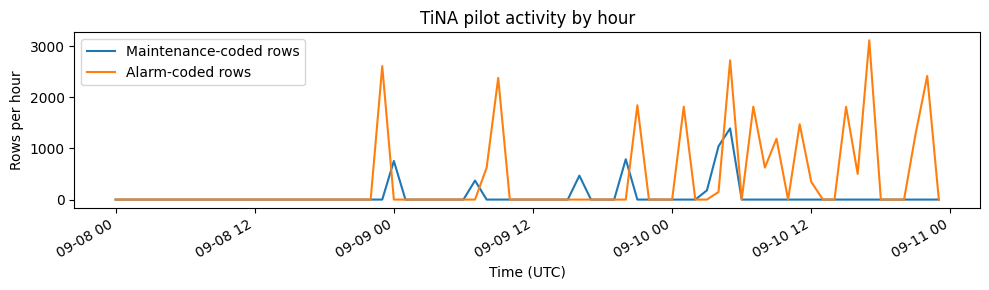

In [8]:
# Each new active run starts one maintenance episode. This pilot has one-second cadence.
active = pilot['m_id'] != 'none'
starts = active & ~active.shift(1).fill_null(False)
episode_ids = starts.cast(pl.UInt32).cum_sum()
episodes = (pilot.with_columns(episode_id=episode_ids)
    .filter(pl.col('m_id') != 'none')
    .group_by('episode_id').agg(
        pl.col('unix').min().alias('start_unix'),
        pl.col('unix').max().alias('end_unix'),
        pl.col('m_id').unique().sort().alias('maintenance_codes'),
        pl.col('m_subid').unique().sort().alias('subtype_codes'),
        (pl.col('alarms') != 'none').sum().alias('alarm_rows_during'),
    ).sort('start_unix').with_columns(
        (pl.col('end_unix') - pl.col('start_unix') + 1).alias('duration_seconds'),
        (pl.col('start_unix') - pl.col('end_unix').shift(1) - 1).alias('gap_since_previous_seconds'),
    ))
alarm_before = [pilot.filter((pl.col('unix') >= s - 1800) &
                             (pl.col('unix') < s) &
                             (pl.col('alarms') != 'none')).height
                for s in episodes['start_unix'].to_list()]
episodes = episodes.with_columns(pl.Series('alarm_rows_preceding_30m', alarm_before))
event_table = episodes.with_columns(
    pl.from_epoch('start_unix', time_unit='s').dt.strftime('%Y-%m-%d %H:%M:%S').alias('start_utc'),
    pl.from_epoch('end_unix', time_unit='s').dt.strftime('%Y-%m-%d %H:%M:%S').alias('end_utc'),
    pl.col('maintenance_codes').list.join(',').alias('m_id'),
    pl.col('subtype_codes').list.join(',').alias('m_subid'),
).select(
    'episode_id', 'start_utc', 'end_utc', 'duration_seconds',
    'gap_since_previous_seconds', 'm_id', 'm_subid',
    'alarm_rows_preceding_30m', 'alarm_rows_during'
).to_pandas()
display(event_table)
recovery = pl.Series('recovery', [False] * pilot.height)
for end in episodes['end_unix'].to_list():
    recovery = recovery | ((timestamps > end) & (timestamps <= end + 1800) & ~active)
train_end = timestamps[int(pilot.height * 0.70)]
validation_end = timestamps[int(pilot.height * 0.85)]
onsets = episodes['start_unix']
split_counts = {
    'train': (onsets < train_end).sum(),
    'validation': ((onsets >= train_end) & (onsets < validation_end)).sum(),
    'test': (onsets >= validation_end).sum(),
}
print(f'Distinct episodes: {episodes.height}')
print(f'Rows in provisional 30-minute recovery windows: {recovery.sum():,}')
print(f'Episodes in chronological train/validation/test: {split_counts}')
print('Chronological split boundaries (UTC):',
      datetime.fromtimestamp(train_end, tz=timezone.utc).isoformat(),
      datetime.fromtimestamp(validation_end, tz=timezone.utc).isoformat())
eligible_rows = pilot.height - active.sum() - recovery.sum()
print(f'Rows eligible after active-maintenance and provisional recovery exclusions: {eligible_rows:,}')
if episodes['duration_seconds'].sum() != active.sum():
    raise ValueError('Episode durations do not account for every maintenance-coded row.')
if (recovery & active).any() or sum(split_counts.values()) != episodes.height:
    raise ValueError('Recovery mask or chronological episode counts are inconsistent.')
if split_counts['test'] == 0:
    print('No future-maintenance model accuracy is reported: the test period has no maintenance onset.')

# Descriptive hourly row counts; rows are not independent events.
hourly = (pilot.select(
    pl.from_epoch('unix', time_unit='s').alias('time_utc'),
    (pl.col('m_id') != 'none').cast(pl.Int8).alias('maintenance_rows'),
    (pl.col('alarms') != 'none').cast(pl.Int8).alias('alarm_rows'),
).group_by_dynamic('time_utc', every='1h').agg(
    pl.col('maintenance_rows').sum(), pl.col('alarm_rows').sum()
).sort('time_utc'))
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(hourly['time_utc'].to_list(), hourly['maintenance_rows'].to_list(), label='Maintenance-coded rows')
ax.plot(hourly['time_utc'].to_list(), hourly['alarm_rows'].to_list(), label='Alarm-coded rows')
ax.set(title='TiNA pilot activity by hour', xlabel='Time (UTC)', ylabel='Rows per hour')
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Week 3 interpretation and next steps

Verified findings and provisional decisions:

- Verified timestamp and sampling interval: `unix` in UTC seconds; 259,200 unique, ascending timestamps at an exact one-second cadence.
- No null, NaN, infinite, or maintenance/subtype mismatch values were found. Eight constant sensor columns require reassessment on broader data; two string sensor columns require encoding.
- Maintenance/alarm codes present: `m_id` M4/M9; `m_subid` MS3/MS5/MS6; alarms A5/A12/A13/A23/A34/A35/A95/A96/A97/A111/A115/A116/A118/A128.
- The 4,994 maintenance rows form six contiguous episodes lasting 371–1,391 seconds. The shortest gap between episodes is 3,765 seconds. Only one episode has alarm rows in the preceding 30 minutes; this is not enough to establish an alarm predictor.
- Excluding current maintenance and a provisional 30-minute recovery interval after each episode leaves 243,406 pilot rows. The recovery rule is not finalized.
- A chronological 70/15/15 split places 4/2/0 episodes in train/validation/test. A test set without events cannot support meaningful predictive accuracy. Expand the observation period before Naive Bayes or other baseline evaluation.
- Select features using training data only; exclude `m_id`, `m_subid`, and information not available at prediction time. Report accuracy alongside precision, recall, F1, PR-AUC, and event-level warning coverage.
- Candidate prediction horizons remain 30 minutes, 1 hour, and 4 hours. Finalize the target and recovery rule during the later target-design stage, using a broader chronological sample.

## Week 3 exploratory baseline: six complete days

The three-day pilot cannot evaluate warning ability because its test segment contains no maintenance onset. This additional, **preliminary** check uses the pinned official partitions from September 7–12, 2017 (518,400 one-second rows, nine episodes). The original pilot analysis above is unchanged.

The model table has one row per complete minute. Predictors are current-minute means and standard deviations of numeric `FEATURE` sensors only; `m_id`, `m_subid`, and `alarms` are never predictors. The target is a *new maintenance episode starting within the next 30 minutes*. Active-maintenance minutes and a provisional 30-minute post-event recovery are excluded. The last 30 minutes of each split are purged to prevent target windows crossing split boundaries.

Training is September 7–10 (six events), validation is September 11 (one event), and the date-held-out test is September 12 (two events). These dates were selected after checking where events occur, so this is not an independent prospective test. Median imputation, variance filtering, scaling, and top-20 univariate feature selection are fitted on training only. A most-frequent dummy and Gaussian Naive Bayes both use a fixed 0.5 score threshold. This is an early workflow check, **not** a credible estimate of performance on new mining machines.

In [ ]:
from src.week3_baseline import run_analysis

baseline = run_analysis()
print('Verified rows / episodes:', baseline['source_rows'], '/', baseline['maintenance_episodes'])
print('Episode counts by split:', baseline['episode_counts'])
print('Training positive / eligible minutes:', baseline['training_positive_minutes'], '/', baseline['training_minutes'])
print('Training-only selected features:', ', '.join(baseline['selected_features']))
for split_name, rows in baseline['results'].items():
    print('\n' + split_name.title() + ' metrics (fixed 0.5 threshold)')
    display(pl.DataFrame(rows).to_pandas())

### Interpretation

High accuracy can hide missed events: on the test day the dummy's 95.5% accuracy accompanies 0/2 episode coverage. Gaussian Naive Bayes covers 2/2 test episodes but generates 626 false-alarm minutes (eight runs), with only 53.1% accuracy and 8.8% precision. These are descriptive pilot results from **two** test events, not a validated claim that Naive Bayes predicts maintenance well. The top-20 feature names are anonymized and should not be assigned physical component meanings.

Next: obtain substantially more chronological data and events, check drift and alternate horizons/recovery rules, and evaluate operational false alarms. Do not tune to the test day or report this as a deployment-ready model. The separate OpenCV track remains an untrained image-intake starter.